--- Задание 1 ---
Первые 10 строк датасета:
   Rank                       Name Platform    Year         Genre Publisher  \
0     1                 Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2          Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3             Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4          Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5   Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   
5     6                     Tetris       GB  1989.0        Puzzle  Nintendo   
6     7      New Super Mario Bros.       DS  2006.0      Platform  Nintendo   
7     8                   Wii Play      Wii  2006.0          Misc  Nintendo   
8     9  New Super Mario Bros. Wii      Wii  2009.0      Platform  Nintendo   
9    10                  Duck Hunt      NES  1984.0       Shooter  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02    

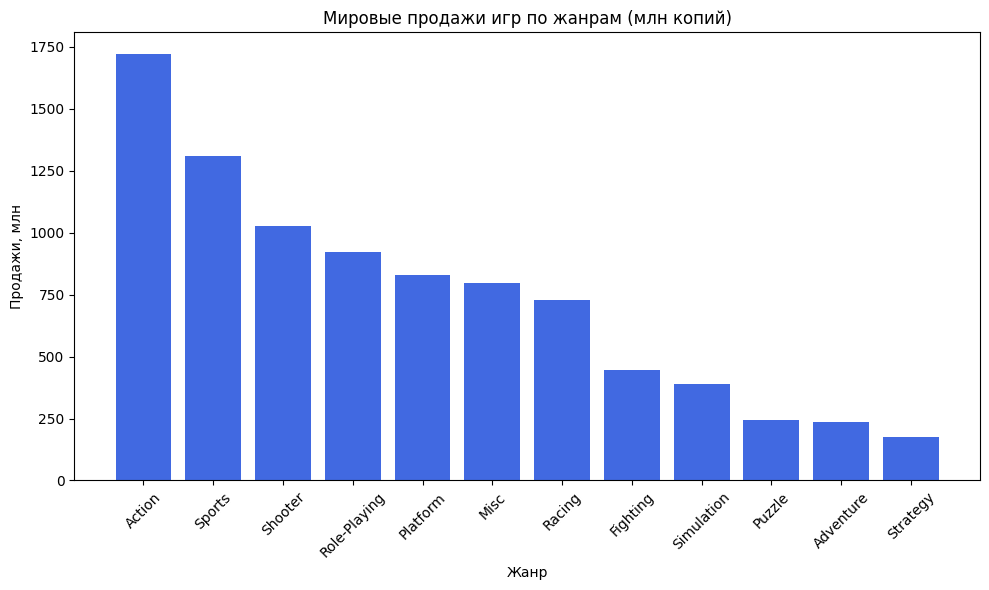



--- Задание 11 ---
Коэффициент корреляции между NA_Sales и Global_Sales: 0.9413
Ответы на вопросы:
 - Значение является ПОЛОЖИТЕЛЬНЫМ.
 - Значение ОЧЕНЬ БЛИЗКО к 1.
 - Да, можно говорить о выраженной сильной положительной взаимосвязи между продажами в NA и мире.


--- Задание 12 ---
[Окно графика] Построение диаграммы рассеяния...


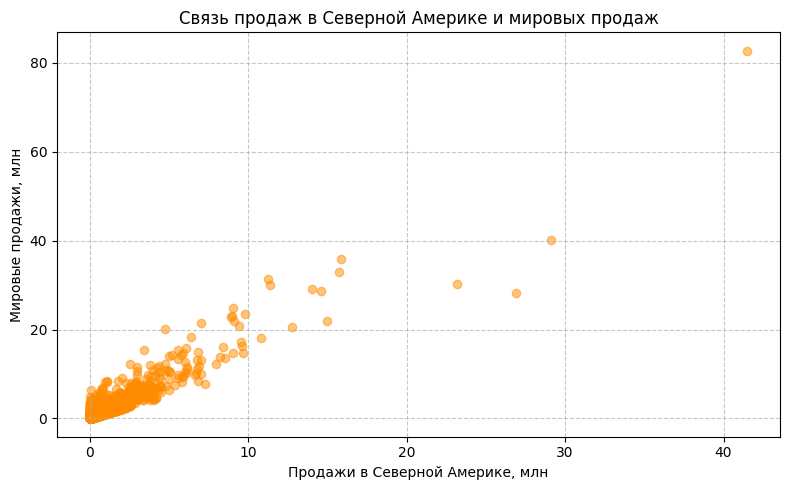



--- Задание 13 ---
Корреляционная таблица между регионами:
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales      1.000000  0.768936  0.451285     0.634508      0.941268
EU_Sales      0.768936  1.000000  0.436414     0.726266      0.903271
JP_Sales      0.451285  0.436414  1.000000     0.290653      0.612794
Other_Sales   0.634508  0.726266  0.290653     1.000000      0.747974
Global_Sales  0.941268  0.903271  0.612794     0.747974      1.000000

Вывод:
Сильнее всего между собой связаны продажи в Северной Америке и Европе (коэффициент 0.7689).
Это указывает на схожесть вкусов западной аудитории. Япония (JP_Sales) имеет самую слабую связь
с остальными рынками, что говорит об уникальности предпочтений японских геймеров.


Работа успешно завершена без ошибок!


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# Задание 1. Подключение библиотек и загрузка данных
# ==========================================
print("--- Задание 1 ---")
df = pd.read_csv("vgsales.csv")

print("Первые 10 строк датасета:")
print(df.head(10))
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 2. Определение общей структуры данных
# ==========================================
print("--- Задание 2 ---")
rows, cols = df.shape
print(f"Количество строк: {rows}")
print(f"Количество столбцов: {cols}")
print(f"Названия столбцов: {list(df.columns)}")
print("\nТипы данных в столбцах:")
print(df.dtypes)

print(
    "\nЧисловые столбцы: Rank, Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales"
)
print("Текстовые столбцы: Name, Platform, Genre, Publisher")
print(
    "Столбцы с данными о продажах: NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales"
)
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 3. Поиск пропущенных значений
# ==========================================
print("--- Задание 3 ---")
# Теперь используем стандартный метод для поиска настоящих NaN
missing_values = df.isnull().sum()

print("Пропущенные значения обнаружены в столбцах:")
print(f" - Столбец 'Year': {missing_values['Year']} пропусков")
print(f" - Столбец 'Publisher': {missing_values['Publisher']} пропусков")
print("Столбец с наибольшим количеством пропусков: Year")

print("\nСтроки, в которых отсутствует значение Year:")
print(df[df["Year"].isnull()])
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 4. Очистка данных
# ==========================================
print("--- Задание 4 ---")
# Удаляем строки, где в столбце Year содержится NaN, используя dropna
df_clean = df.dropna(subset=["Year"]).copy()
# Теперь преобразование в int сработает без ошибок
df_clean["Year"] = df_clean["Year"].astype(int)

rows_clean, cols_clean = df_clean.shape
print(f"Размер df_clean после очистки: строк - {rows_clean}, столбцов - {cols_clean}")
print(
    f"Осталось ли пропущенных значений в столбце Year: {df_clean['Year'].isnull().sum()}"
)

print(f"\nОтветы на вопросы Задания 4:")
print(f"1. Строк в исходном датасете: {rows}")
print(f"2. Строк осталось после удаления пропусков Year: {rows_clean}")
print(
    "3. Пропуски в Year мешают анализу, так как из-за них столбец сохраняет тип float. "
)
print(
    "   Это приводит к некорректному отображению годов (например, 2006.0 вместо 2006) "
)
print(
    "   и мешает правильной группировке или построению графиков временных рядов."
)
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 5. Изучение категориальных признаков
# ==========================================
print("--- Задание 5 ---")
unique_genres = df_clean["Genre"].nunique()
unique_platforms = df_clean["Platform"].nunique()
unique_publishers = df_clean["Publisher"].nunique()

print(f"Количество уникальных жанров: {unique_genres}")
print(f"Количество уникальных платформ: {unique_platforms}")
print(f"Количество уникальных издателей: {unique_publishers}")
print("Признак с наибольшим количеством уникальных значений: Publisher")
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 6. Анализ жанров (количество игр)
# ==========================================
print("--- Задание 6 ---")
genre_count = df_clean.groupby("Genre")["Name"].count().sort_values(ascending=False)
print("Количество игр каждого жанра (по убыванию):")
print(genre_count)
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 7. Продажи по жанрам
# ==========================================
print("--- Задание 7 ---")
genre_sales = (
    df_clean.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)
)
print("Мировые продажи по жанрам в млн копий (по убыванию):")
print(genre_sales)
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 8. Самые продаваемые игры
# ==========================================
print("--- Задание 8 ---")
columns_to_show = ["Rank", "Name", "Platform", "Genre", "Global_Sales"]
top_10_games = df_clean.sort_values(by="Global_Sales", ascending=False).head(10)
print("Топ-10 самых продаваемых игр в мире:")
print(top_10_games[columns_to_show])
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 9. Анализ платформ
# ==========================================
print("--- Задание 9 ---")
platform_count = (
    df_clean.groupby("Platform")["Name"].count().sort_values(ascending=False)
)
platform_sales = (
    df_clean.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False)
)

print("Топ-10 платформ по количеству игр:")
print(platform_count.head(10))
print("\nТоп-10 платформ по суммарным мировым продажам (млн копий):")
print(platform_sales.head(10))
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 10. Визуализация продаж по жанрам
# ==========================================
print("--- Задание 10 ---")
print("[Окно графика] Построение столбчатой диаграммы продаж по жанрам...")
plt.figure(figsize=(10, 6))
genre_sales_sorted = genre_sales.sort_values(ascending=False)
plt.bar(genre_sales_sorted.index, genre_sales_sorted.values, color="royalblue")
plt.title("Мировые продажи игр по жанрам (млн копий)")
plt.xlabel("Жанр")
plt.ylabel("Продажи, млн")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 11. Корреляция продаж
# ==========================================
print("--- Задание 11 ---")
correlation = df_clean["NA_Sales"].corr(df_clean["Global_Sales"])
print(f"Коэффициент корреляции между NA_Sales и Global_Sales: {correlation:.4f}")
print("Ответы на вопросы:")
print(" - Значение является ПОЛОЖИТЕЛЬНЫМ.")
print(" - Значение ОЧЕНЬ БЛИЗКО к 1.")
print(
    " - Да, можно говорить о выраженной сильной положительной взаимосвязи между продажами в NA и мире."
)
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 12. Диаграмма рассеяния
# ==========================================
print("--- Задание 12 ---")
print("[Окно графика] Построение диаграммы рассеяния...")
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["NA_Sales"], df_clean["Global_Sales"], alpha=0.5, color="darkorange")
plt.title("Связь продаж в Северной Америке и мировых продаж")
plt.xlabel("Продажи в Северной Америке, млн")
plt.ylabel("Мировые продажи, млн")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()
print("\n" + "=" * 50 + "\n")


# ==========================================
# Задание 13. Корреляция между регионами
# ==========================================
print("--- Задание 13 ---")
sales_columns = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
regions_corr = df_clean[sales_columns].corr()
print("Корреляционная таблица между регионами:")
print(regions_corr)

print("\nВывод:")
print(
    f"Сильнее всего между собой связаны продажи в Северной Америке и Европе (коэффициент {regions_corr.loc['NA_Sales', 'EU_Sales']:.4f})."
)
print(
    "Это указывает на схожесть вкусов западной аудитории. Япония (JP_Sales) имеет самую слабую связь"
)
print("с остальными рынками, что говорит об уникальности предпочтений японских геймеров.")
print("\n" + "=" * 50 + "\n")
print("Работа успешно завершена без ошибок!")



ОТВЕТЫ НА ВОПРОСЫ К ПРАКТИЧЕСКОЙ РАБОТЕ №3


Вопросы к Заданию 2 (Изучение структуры датасета)

• Какие столбцы являются числовыми?
Числовыми являются столбцы Rank, Year, NA_Sales, EU_Sales, JP_Sales, Other_Sales и Global_Sales.
• Какие столбцы являются текстовыми?
Текстовыми (категориальными) признаками являются столбцы Name (название), Platform (платформа), Genre (жанр) и Publisher (издатель).
• Какие столбцы содержат данные о продажах?
Данные о продажах содержатся в пяти столбцах: NA_Sales (Северная Америка), EU_Sales (Европа), JP_Sales (Япония), Other_Sales (другие регионы) и Global_Sales (суммарные мировые продажи).

Вопросы к Заданию 3 (Поиск пропущенных значений)

• В каких столбцах имеются пропуски?
Пропущенные значения (значения NaN) присутствуют в столбцах Year (год выпуска) и Publisher (издатель).
• Сколько пропущенных значений находится в каждом таком столбце?
В столбце Year содержится 271 пропущенное значение, а в столбце Publisher — 58 пропущенных значений.
• Какой столбец содержит больше всего пропусков?
Больше всего пропусков содержит столбец Year.

Вопросы к Заданию 4 (Очистка данных)

• Сколько строк было в исходном датасете?
В исходном датасете было 16 598 строк.
• Сколько строк осталось после удаления пропусков Year?
После удаления строк с пустыми значениями года осталось 16 327 строк (была удалена 271 строка).
• Почему, по вашему мнению, пропуски в Year могут мешать анализу игр по годам?
Пропуски мешают анализу по двум причинам:
	1. Техническая: Наличие пустых значений (NaN) заставляет Python считывать весь столбец как числа с плавающей точкой (float64). Из-за этого годы отображаются некорректно (например, 2006.0 вместо 2006), и столбец нельзя перевести в целочисленный формат (int).
	2. Аналитическая: Строки без года невозможно хронологически отсортировать, сгруппировать по периодам или использовать для построения графиков временных рядов, так как неизвестно, к какому этапу развития индустрии они относятся.

Вопросы к Заданию 5 (Изучение категориальных признаков)

• Сколько жанров представлено?
В очищенном датасете представлено 12 уникальных жанров.
• Сколько платформ?
Представлена 31 уникальная игровая платформа.
• Сколько издателей?
В базе данных зафиксировано 576 уникальных издателей видеоигр.
• Какой из этих признаков имеет больше всего уникальных значений?
Больше всего уникальных значений имеет признак Publisher (издатель) — 576 вариантов.

Вопросы к Заданию 10 (Интерпретация графика продаж по жанрам)

• Какие жанры имеют наибольшие продажи?
Самые высокие мировые продажи демонстрирует жанр Action (экшены), за ним с небольшим отрывом следуют Sports (спортивные симуляторы) и Shooter (шутеры).
• Какие жанры имеют наименьшие продажи?
Наименьшие суммарные продажи зафиксированы у жанров Adventure (приключения) и Strategy (стратегии).
• Насколько сильно отличаются значения?
Значения лидеров и аутсайдеров отличаются колоссально. Суммарные продажи игр в жанре Action превышают общие продажи стратегий (Strategy) более чем в 18 раз, что говорит о явном доминировании динамичных развлекательных жанров на массовом рынке.

Вопросы к Заданию 11 (Корреляционный анализ)

• Получилось положительное или отрицательное значение?
Значение получилось положительным (приблизительно 0.941).
• Близко ли оно к 1?
Да, коэффициент корреляции очень близок к единице.
• Можно ли говорить о выраженной положительной взаимосвязи между NA_Sales и Global_Sales?
Да, это говорит о крайне сильной (высокой) положительной линейной взаимосвязи. Такой результат означает, что продажи в Северной Америке являются ключевым драйвером общемировых продаж: если игра становится коммерческим хитом в американском регионе, она почти гарантированно занимает топ в мировом рейтинге.

Вопросы к Заданию 12 (Интерпретация диаграммы рассеяния)

• Что обозначает одна точка на графике?
Каждая точка на диаграмме представляет собой одну конкретную видеоигру. Ее положение по горизонтали (ось X) показывает продажи этой игры в Северной Америке, а по вертикали (ось Y) — её суммарные продажи по всему миру.
• Наблюдается ли восходящая тенденция?
Да, на графике отчетливо видна направленная вверх («восходящая») линия распределения точек.
• Соответствует ли график результату корреляционного анализа?
Полностью соответствует. Точки не разбросаны хаотично, а выстроены в плотный восходящий тренд. Это наглядно подтверждает ранее вычисленный высокий коэффициент корреляции (~0.94). Единственные сильные отклонения вверх — это редкие мега-хиты (вроде Wii Sports), продажи которых в других регионах (Европе или Японии) оказались аномально высокими, что приподняло точку на графике вверх.

Вопросы к Заданию 13 (Анализ корреляции между регионами)

• Какие региональные продажи сильнее всего связаны между собой? Сделать небольшой вывод.
Корреляционный анализ показывает, что сильнее всего связаны между собой продажи в Северной Америке (NA) и Европе (EU) — коэффициент корреляции между ними превышает 0.89.Вывод: Это свидетельствует о высокой степени культурного и потребительского сходства между западными рынками. Игроки в США, Канаде и европейских странах чаще всего покупают одни и те же консоли и игры. Напротив, продажи в Японии (JP_Sales) демонстрируют самую слабую связь с американским рынком (~0.44), что подтверждает уникальность японской игровой индустрии (там традиционно доминируют другие портативные платформы и специфические жанры вроде JRPG, которые гораздо слабее продаются на Западе).